In [118]:
import numpy as np
import matplotlib.pyplot as plt

import sys
# sys.path.append("..")

import scipy.sparse as sps
from scipy.sparse.linalg import cg as sp_cg


from trips.test_problems.Tomography import Tomography
import astra

import jlinops

import numpy as np
import math

from jlinops.base import _CustomLinearOperator
# from .util import get_device

# from ias import IASSolver

from trips.utilities.phantoms import shepp_logan

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')


from PIL import Image
import numpy as np

CMAP = "gray"

import sys
import os

# Go three directories up
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

from msolver import MMGKS, IASGKS, VanillaGKS

from pinv import CGWeightedNeumann2DPinvOperatorGPU

# Test problem

In [2]:
np.random.seed(0)
theta_max = np.pi
#Tomo = Tomography (geom="fanflat", CommitCrime=True, theta_max=theta_max)
#Tomo = Tomography (geom="fanflat", CommitCrime=True)
Tomo = Tomography (geom="parallel", CommitCrime=False, theta_max=theta_max)
views = 28
noise_percent = 0.01 # percent of maximum of noiseless signal A x_true
N = 256

x_true = shepp_logan(N)
img_shape = x_true.shape
nx, ny = x_true.shape
(F , b_true , p , q , AforMatrixOperation ) = Tomo.gen_data( x_true , nx , ny , views )

noise_stdev = noise_percent*np.amax(b_true)
noise_var = noise_stdev**2
print(f"Noise level: {noise_percent}")
print(f"Noise stdev: {noise_stdev}")
print(f"Noise var: {noise_var}")


b_noisy = b_true.flatten() + noise_stdev*np.random.normal(size=b_true.flatten().shape)
b_noisy_shaped = b_noisy.reshape((p,q))
noisy_signal = b_noisy.flatten()
m, n = F.shape


# Define linear operator implementing A
_matvec_fn = lambda x: F.matvec(x)
_rmatvec_fn = lambda x: F.rmatvec(x)
A = _CustomLinearOperator( (m,n), _matvec_fn, _rmatvec_fn, device="cpu")

# Underdetermined rate:
underdetermined_rate = noisy_signal.size/(nx*ny)
print(f"Underdetermined rate: {underdetermined_rate}")

settings
no crime
Noise level: 0.01
Noise stdev: 0.6781836700439453
Noise var: 0.4599330903142749
Underdetermined rate: 0.1546630859375


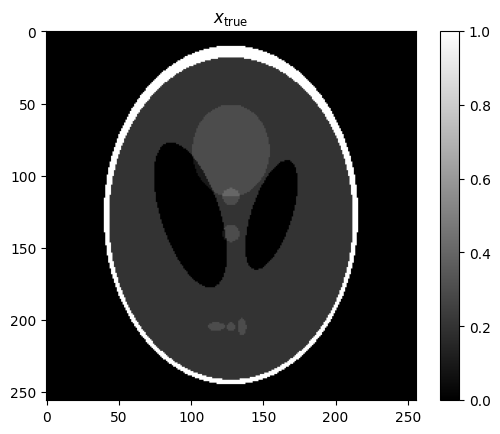

In [3]:
plt.imshow(x_true.reshape((nx,ny)), cmap=CMAP)
plt.title("$x_{\\text{true}}$")
plt.colorbar()
plt.show()

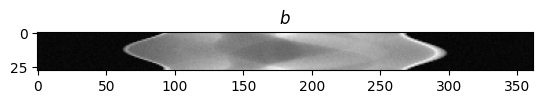

In [4]:
plt.imshow(b_noisy_shaped, cmap=CMAP)
plt.title("$b$")
plt.show()

In [5]:
# # fbp_recon = Tomo.A.reconstruct("SIRT", noisy_signal, iterations=200)
# fbp_recon = Tomo.A.reconstruct("FBP", noisy_signal, iterations=1)

In [6]:
# plt.imshow(np.clip(fbp_recon, a_min=0.0, a_max=None), cmap=CMAP)
# plt.colorbar()
# plt.show()

# L2 GKS

In [7]:
# Set method
method = "dp"

Lmat = jlinops.build_neumann2d_sparse_matrix(img_shape)
L = jlinops.Neumann2D(img_shape)

# # Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     delta = 1e-15
#     for j in range(10):
#         try:
#             return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=delta)
#         except:
#             delta *= 10
#     return None


K = np.ones(n)/np.linalg.norm(np.ones(n))
K = jlinops.MatrixLinearOperator(K)

#L = jlinops.Neumann2D(img_shape)
# def Lpinv_factory(w, *args, **kwargs):
#     return jlinops.CGWeightedNeumann2DPinvOperator(img_shape, weights=w, tol=1e-4, *args, **kwargs)

def Lpinv_factory(w, *args, **kwargs):
    return CGWeightedNeumann2DPinvOperatorGPU(img_shape, weights=w, tol=1e-4, *args, **kwargs)


#err_norm_sq = len(b) # in expectation

q = 1.0
epsilon = 1e-4
weight_params = {
    "q": q,
    "epsilon": epsilon,
}


# Build solvers

gks_solver = VanillaGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmgks_solver = MMGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

# Misc
AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b_noisy)

# Run all methods

In [8]:
vdata = gks_solver.solve(n_iter=50, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params={},
                                    regparam_kwargs={"eta":1.01})

print("Finished GKS.")


1e-14
1e-14
1e-14
99.49756234935755
114.41712066935968
139.22785426486186
144.30233890995035
152.72695124143092
152.32495240473017
147.4483921564566
147.74017742577462
153.03991274742444
154.9532533393187
153.16349914283225
153.82757225834078
155.6838710379785
154.66086924591954
154.1807942771552
154.92221949063227
155.3819158740577
154.8801482786828
154.91251798652908
155.4127548273512
155.32272763400562
155.0187817594236
155.41116471009164
155.2453673156546
155.05969515346877
155.28961191845517
155.31198673030033
155.10836795256333
155.39101912338248
155.2301034423309
155.22274485444902
155.34608457748257
155.2052327763825
155.296179643504
155.29950475345365
155.23955806222992
155.34784803585745
155.25606945205863
155.28528757082975
155.3169952521616
155.2600085744422
155.28877668249575
155.30439476579855
155.27410009553043
155.29690540463267
155.2895773269173
155.28451358312438
Finished GKS.


In [9]:
data = mmgks_solver.solve(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

print("Finished S-GKS.")


resdata = mmgks_solver.solve(n_iter=100, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=15)

print("Finished restarting S-GKS.")


recdata = mmgks_solver.solve(n_iter=100, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=None, dim_min=5, dim_max=15)

print("Finished recycling S-GKS.")


pdata = mmgks_solver.solve_with_priorconditioning(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

print("Finished PS-GKS.")


Augmented basis with initial guess!


9.15836875560494
9.089447098819065
9.155907489158723
9.204182763908214
9.317657477527755
9.628303303308169
9.79379772754536
9.759463326800033
9.769237844842962
9.738793097313179
9.800852029560218
9.792857277502646
9.821137192036932
9.806739896226938
9.764586843975742
9.734874673169582
9.702073332937342
9.671742616061014
9.65592128557453
9.641433106022337
9.627920386685002
9.61936539973158
9.610205856074371
9.601081034716968
9.594683610365703
9.588948693165895
9.584926996366589
9.58397905146866
9.584631565153428
9.584185530883772
9.585084906629746
9.591583170947224
9.603127255989143
9.618348043541198
9.63269093420166
9.640012953650396
9.656628390829532
9.677155763143627
9.707771047788711
9.728123157113496
9.756878514592517
9.77961253407139
9.776907585551086
9.776074690748496
9.782070830089156
9.7854459426451
9.786466843058392
9.786004791407727
9.787170146741836
9.785984317255917
Finished S-GKS.
Augmented basis with initial guess!


9.15836875560494
9.089447098819065
9.155907489158723
9.204182763908214
9.317657477527755
9.628303303308169
9.79379772754536
9.759463326800033
9.769237844842962
9.75430750645811
9.215171807602184
7.297384109839773
7.786839642515737
7.990781963540095
8.331979056569736
8.443580402265681
8.330456889404653
8.491674781618677
9.058697296756112
9.491729436374424
9.13778198132548
8.488056693849638
8.40732917539242
8.39604505310216
8.839286533871203
7.946305688659465
8.014344306594545
8.071830283864323
8.151060281417369
8.148300312522034
8.18901909273391
8.194997153546131
8.179832721408863
8.17682863719272
8.1698872820242
8.212553198569504
8.203182132057156
8.203069744603226
8.170292004649658
8.105386218481254
8.113490931028139
8.118111511109582
8.117160697484115
8.159693900908245
8.18863614765028
8.234030885254205
8.290767963827046
8.291065656308595
8.362979145069586
8.253922704479772
8.121568218041391
8.11978718380644
8.118423040169171
8.124091177145132
8.118437064153154
8.107376273796238
8.15

9.15836875560494
9.089447098819065
9.155907489158723
9.204182763908214
9.317657477527755
9.628303303308169
9.79379772754536
9.759463326800033
9.769237844842962
9.738793097313179
9.800852029560218
9.792857277502646
9.821137192036932
9.806739896226938
9.764586843975742
9.734874673169582
9.702073332937342
9.671742616061014
9.65592128557453
9.641433106022337
9.627920386685002
9.61936539973158
9.610205856074371
9.601081034716968
9.594683610365703
9.588948693165895
9.584926996366589
9.58397905146866
9.584631565153428
9.584185530883772
9.585084906629746
9.591583170947224
9.603127255989143
9.618348043541198
9.63269093420166
9.640012953650396
9.656628390829532
9.677155763143627
9.707771047788711
9.728123157113496
9.756878514592517
9.77961253407139
9.776907585551086
9.776074690748496
9.782070830089156
9.7854459426451
9.786466843058392
9.786004791407727
9.787170146741836
9.785984317255917
9.785176238675422
9.784066782166882
9.782576990261639
9.782811080078659
9.781486878865701
9.781687619356035
9

/home/jlindbloom/Github/IRLS_prec_GSBL/msolver.py:708: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
3.5310263035646545
8.012902278253796
9.348678299499651
10.07501738491247
11.10864986655643
11.818160147852636
11.482449564378042
11.639577892130193
11.862129088180055
12.7134158946802
13.34914404875267
14.011721017054949
14.572882238116703
14.730843401236037
15.301609754519998
14.91947097295233
14.945271287961047
15.183609266488315
15.177122834095371
15.630049933146497
15.716437649598358
15.728358493990143
15.8206052710673
15.805411624483352
15.906120714431545
15.86626799489187
15.946722889436087
15.990046099973025
Finished PS-GKS.


In [10]:
respdata = mmgks_solver.solve_with_priorconditioning(n_iter=100, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01}, restart_dim=5)

print("Finished PS-GKS.")

Augmented basis with initial guess!


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
3.5310263035646545
8.012902278253796
9.348678299499651
10.07501738491247
11.10864986655643
11.818160147852636
11.482449564378042
11.639577892130193
11.862129088180055
12.7134158946802
13.34914404875267
14.011721017054949
14.572882238116703
14.730843401236037
15.301609754519998
14.91947097295233
14.945271287961047
15.183609266488315
15.177122834095371
15.630049933146497
15.716437649598358
15.728358493990143
15.8206052710673
15.805411624483352
15.906120714431545
15.86626799489187
15.946722889436087
15.990046099973025
15.987811620033794
16.094271435122256
16.106080501726467
16.134389022808133
16.12027668606588
16.13935779148253
16.18631873409456
16.195693173764962
16.214538023219184
16.212148310782567
16.234151548207137
16.242423726489495
16.262502282009454
16.26954304460538
16.276929928148604
16.280303396647938
16.287768349167955
16.295610018400154
16.308139

# Some plots

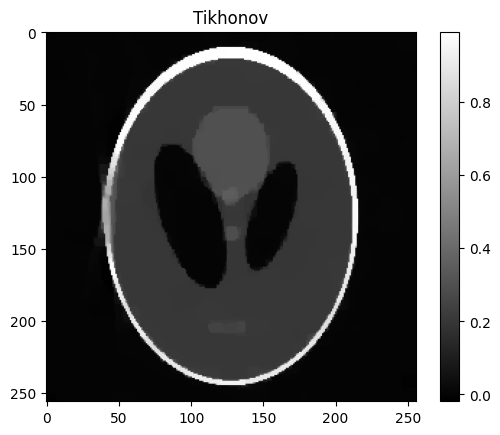

In [19]:
plt.imshow(respdata["x"].reshape((nx,ny)) , cmap="gray")
# plt.imshow(np.clip(vdata["x"].reshape((nx,ny)), a_min=0, a_max=None), cmap="gray")
plt.title("Tikhonov")
plt.colorbar()
plt.show()

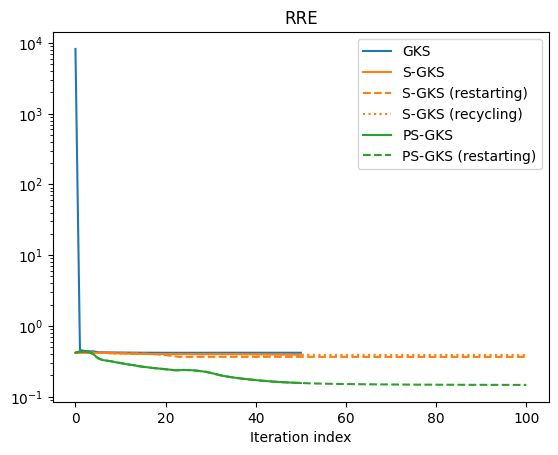

In [42]:
plt.semilogy(vdata["rre_history"], label="GKS")
plt.semilogy(data["rre_history"], label="S-GKS", color="C1")
plt.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["rre_history"], label="PS-GKS", color="C2")
plt.semilogy(respdata["rre_history"], label="PS-GKS (restarting)", color="C2", ls="--")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

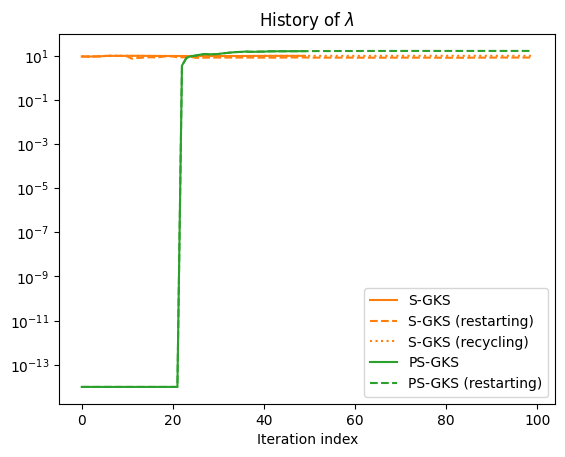

In [20]:
#plt.semilogy(vdata["rre_history"], label="GKS")
plt.semilogy(data["lambda_history"], label="S-GKS", color="C1")
plt.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["lambda_history"], label="PS-GKS", color="C2")
plt.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", color="C2", ls="--")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

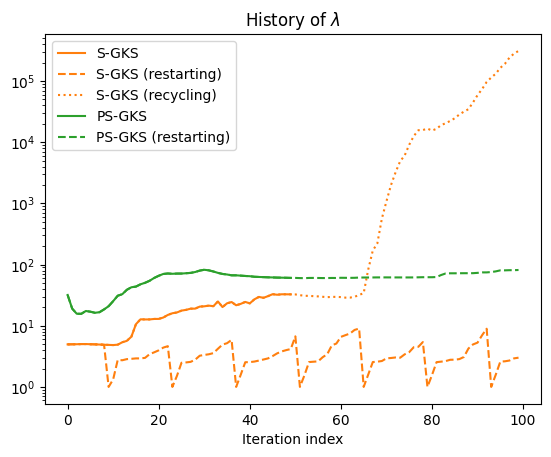

In [24]:
#plt.semilogy(vdata["rre_history"], label="GKS")
plt.semilogy(data["cond_ests"], label="S-GKS", color="C1")
plt.semilogy(resdata["cond_ests"], label="S-GKS (restarting)", color="C1", ls="--")
plt.semilogy(recdata["cond_ests"], label="S-GKS (recycling)", color="C1", ls=":")
plt.semilogy(pdata["cond_ests"], label="PS-GKS", color="C2")
plt.semilogy(respdata["cond_ests"], label="PS-GKS (restarting)", color="C2", ls="--")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

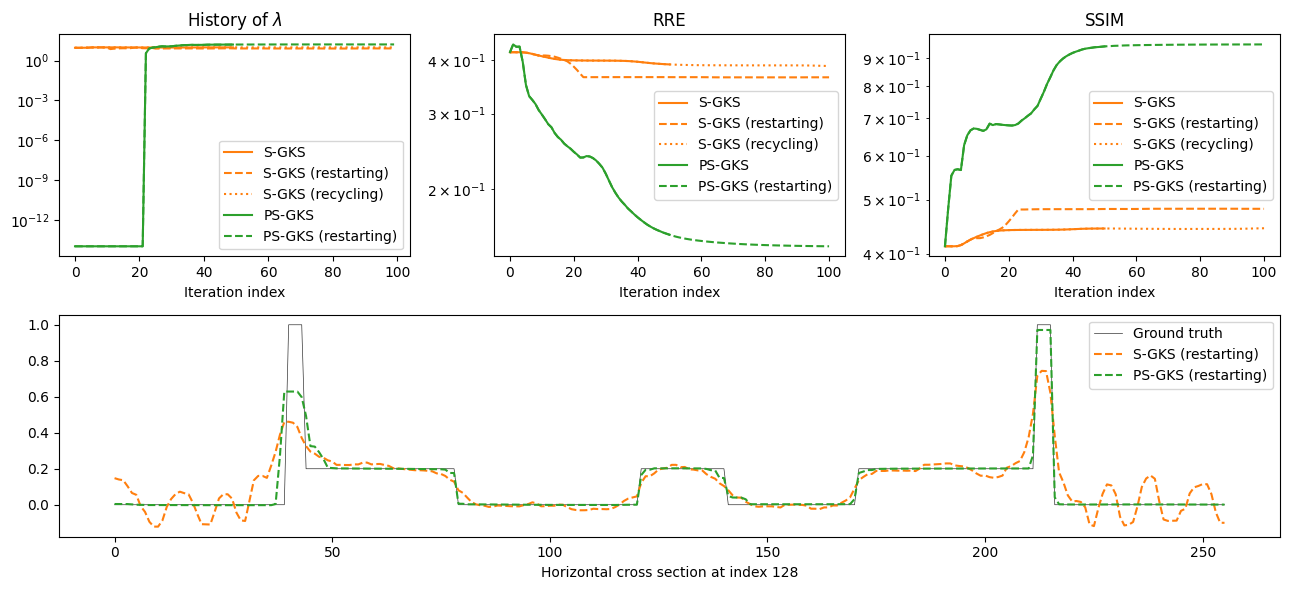

In [136]:
fig = plt.figure(figsize=(13,6))

gs = gridspec.GridSpec(2, 3, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])
ax1.semilogy(data["lambda_history"], label="S-GKS", color="C1")
ax1.semilogy(resdata["lambda_history"], label="S-GKS (restarting)", color="C1", ls="--")
ax1.semilogy(recdata["lambda_history"], label="S-GKS (recycling)", color="C1", ls=":")
ax1.semilogy(pdata["lambda_history"], label="PS-GKS", color="C2")
ax1.semilogy(respdata["lambda_history"], label="PS-GKS (restarting)", color="C2", ls="--")
ax1.set_title("History of $\\lambda$")
ax1.set_xlabel("Iteration index")
ax1.legend()


ax2 = fig.add_subplot(gs[0, 1])
#plt.semilogy(vdata["rre_history"], label="GKS")
ax2.semilogy(data["rre_history"], label="S-GKS", color="C1")
ax2.semilogy(resdata["rre_history"], label="S-GKS (restarting)", color="C1", ls="--")
ax2.semilogy(recdata["rre_history"], label="S-GKS (recycling)", color="C1", ls=":")
ax2.semilogy(pdata["rre_history"], label="PS-GKS", color="C2")
ax2.semilogy(respdata["rre_history"], label="PS-GKS (restarting)", color="C2", ls="--")
ax2.set_title("RRE")
ax2.set_xlabel("Iteration index")
ax2.legend()


ax3 = fig.add_subplot(gs[0, 2])
#plt.semilogy(vdata["rre_history"], label="GKS")
ax3.semilogy(data["ssim_history"], label="S-GKS", color="C1")
ax3.semilogy(resdata["ssim_history"], label="S-GKS (restarting)", color="C1", ls="--")
ax3.semilogy(recdata["ssim_history"], label="S-GKS (recycling)", color="C1", ls=":")
ax3.semilogy(pdata["ssim_history"], label="PS-GKS", color="C2")
ax3.semilogy(respdata["ssim_history"], label="PS-GKS (restarting)", color="C2", ls="--")
ax3.set_title("SSIM")
ax3.set_xlabel("Iteration index")
ax3.legend()


ax4 = fig.add_subplot(gs[1, :]) 
ax4.plot(x_true.reshape(img_shape)[128,:], label="Ground truth", color="k", alpha=0.8, lw=0.5)
ax4.plot(resdata["x"].reshape(img_shape)[128,:], label="S-GKS (restarting)", color="C1", ls="--")
ax4.plot(respdata["x"].reshape(img_shape)[128,:], label="PS-GKS (restarting)", color="C2", ls="--")
ax4.set_xlabel("Horizontal cross section at index 128")
ax4.legend()



fig.tight_layout()
fig.savefig("2d_shepp_performance.png", dpi=250, bbox_inches=None)
fig.savefig("2d_shepp_performance.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()

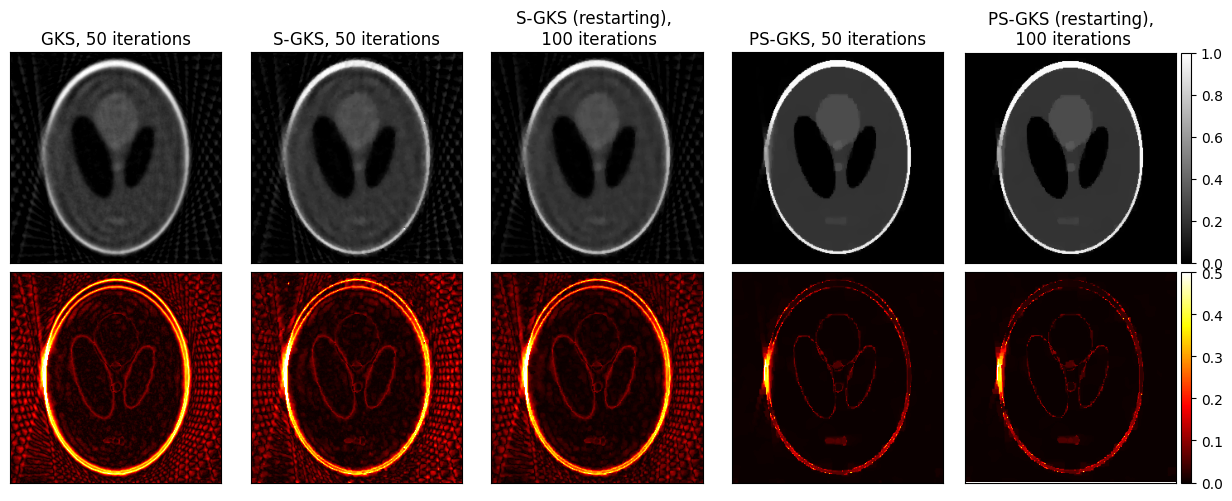

In [114]:
err_cmap = "hot"

vbound = 0.5

fig, axs = plt.subplots(2,5,figsize=(12.5,5))


# Tikhonov
axs[0,0].imshow(vdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,0].set_title("GKS, 50 iterations")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow(np.abs( vdata["x"].reshape(img_shape) - x_true.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])


# S-GKS
axs[0,1].imshow(data["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,1].set_title("S-GKS, 50 iterations")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow(np.abs( data["x"].reshape(img_shape) - x_true.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])


# S-GKS (restarting)
axs[0,2].imshow(resdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,2].set_title("S-GKS (restarting), \n 100 iterations")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow(np.abs( resdata["x"].reshape(img_shape) - x_true.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])


# PS-GKS
axs[0,3].imshow(pdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,3].set_title("PS-GKS, 50 iterations")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow(np.abs( pdata["x"].reshape(img_shape) - x_true.reshape(img_shape) ), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])



# PS-GKS restarting
im = axs[0,4].imshow(respdata["x"].reshape(img_shape), cmap="gray", vmin=0, vmax=1)
axs[0,4].set_title("PS-GKS (restarting),\n 100 iterations")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])
divider = make_axes_locatable(axs[0,4])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)

im = axs[1,4].imshow(np.abs(respdata["x"].reshape(img_shape) - x_true.reshape(img_shape)), cmap=err_cmap, vmin=0, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])
divider = make_axes_locatable(axs[1,4])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)


fig.savefig("2d_shepp_reconstructions.png", dpi=250, bbox_inches=None)
fig.savefig("2d_shepp_reconstructions.eps", format="eps", dpi=250, bbox_inches=None)

fig.tight_layout()

plt.show()

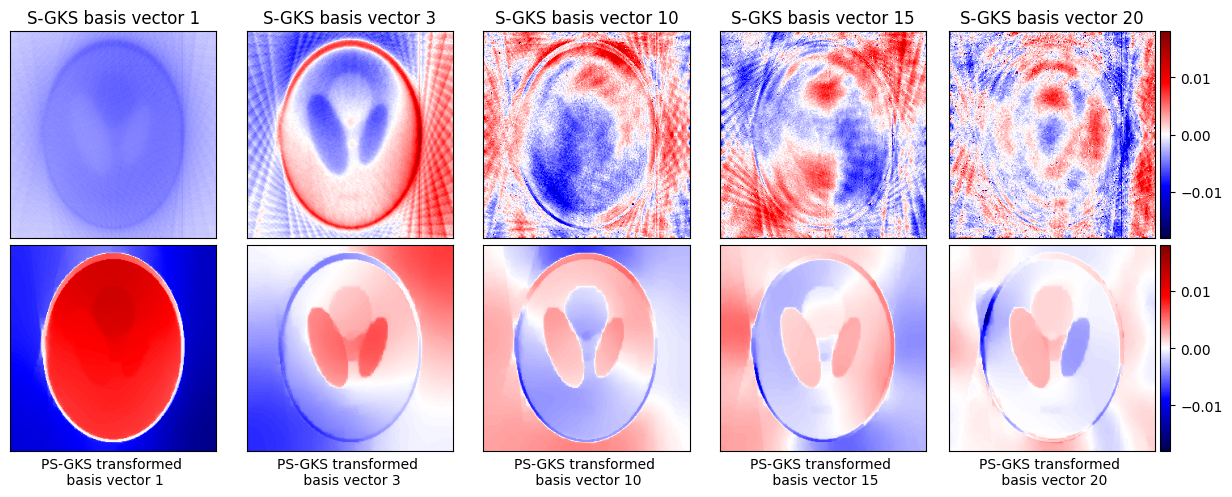

In [117]:
cmap = "seismic"
vbound = 0.018

fig, axs = plt.subplots(2,5,figsize=(12.5,5))

kk = 0

axs[0,0].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[0,0].set_title(f"S-GKS basis vector {kk+1}")
axs[0,0].set_xticks([])
axs[0,0].set_yticks([])

axs[1,0].imshow( (pdata["Lopinv"] @ pdata["V"][:,kk] ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[1,0].set_xticks([])
axs[1,0].set_yticks([])
axs[1,0].set_xlabel(f"PS-GKS transformed \n basis vector {kk+1}")



kk = 2
axs[0,1].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[0,1].set_title(f"S-GKS basis vector {kk+1}")
axs[0,1].set_xticks([])
axs[0,1].set_yticks([])

axs[1,1].imshow( (pdata["Lopinv"] @ pdata["V"][:,kk] ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[1,1].set_xticks([])
axs[1,1].set_yticks([])
axs[1,1].set_xlabel(f"PS-GKS transformed \n basis vector {kk+1}")


kk = 9
axs[0,2].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[0,2].set_title(f"S-GKS basis vector {kk+1}")
axs[0,2].set_xticks([])
axs[0,2].set_yticks([])

axs[1,2].imshow( (pdata["Lopinv"] @ pdata["V"][:,kk] ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[1,2].set_xticks([])
axs[1,2].set_yticks([])
axs[1,2].set_xlabel(f"PS-GKS transformed \n basis vector {kk+1}")


kk = 14
axs[0,3].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[0,3].set_title(f"S-GKS basis vector {kk+1}")
axs[0,3].set_xticks([])
axs[0,3].set_yticks([])

axs[1,3].imshow( (pdata["Lopinv"] @ pdata["V"][:,kk] ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[1,3].set_xticks([])
axs[1,3].set_yticks([])
axs[1,3].set_xlabel(f"PS-GKS transformed \n basis vector {kk+1}")


kk = 19
im = axs[0,4].imshow(data["V"][:,kk].reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[0,4].set_title(f"S-GKS basis vector {kk+1}")
axs[0,4].set_xticks([])
axs[0,4].set_yticks([])
divider = make_axes_locatable(axs[0,4])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)

im = axs[1,4].imshow( (pdata["Lopinv"] @ pdata["V"][:,kk] ).reshape(img_shape), cmap=cmap, vmin=-vbound, vmax=vbound)
axs[1,4].set_xticks([])
axs[1,4].set_yticks([])
axs[1,4].set_xlabel(f"PS-GKS transformed \n basis vector {kk+1}")
divider = make_axes_locatable(axs[1,4])
cax = divider.append_axes("right", size="5%", pad=0.05)
fig.colorbar(im, cax=cax)


fig.savefig("2d_shepp_basis_vectors.png", dpi=250, bbox_inches=None)
fig.savefig("2d_shepp_basis_vectors.eps", format="eps", dpi=250, bbox_inches=None)

fig.tight_layout()

plt.show()

# OLD

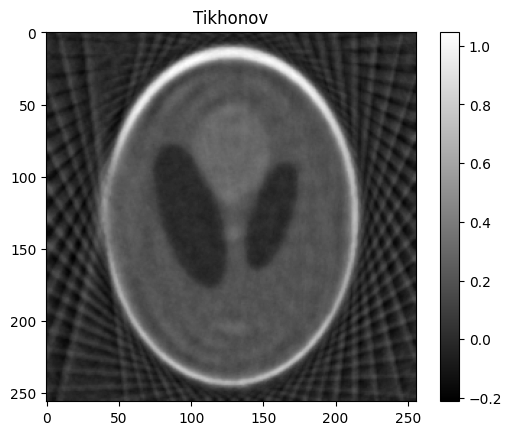

In [95]:
plt.imshow(vdata["x"].reshape((nx,ny)) , cmap="gray")
# plt.imshow(np.clip(vdata["x"].reshape((nx,ny)), a_min=0, a_max=None), cmap="gray")
plt.title("Tikhonov")
plt.colorbar()
plt.show()

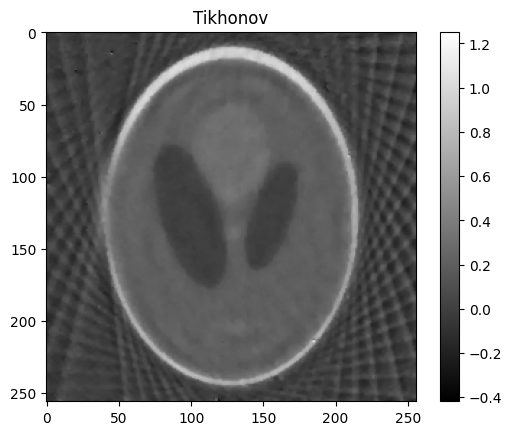

In [11]:
plt.imshow(data["x"].reshape((nx,ny)) , cmap="gray")
# plt.imshow(np.clip(vdata["x"].reshape((nx,ny)), a_min=0, a_max=None), cmap="gray")
plt.title("Tikhonov")
plt.colorbar()
plt.show()

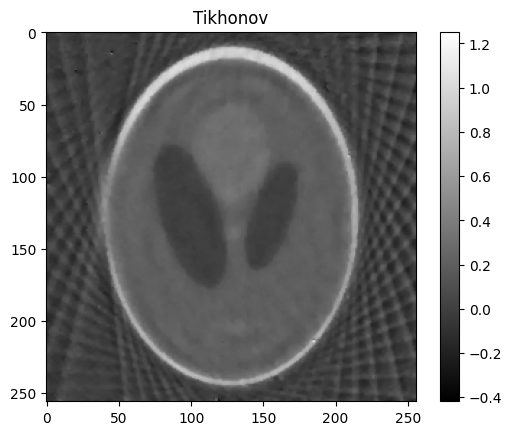

In [12]:
plt.imshow(recdata["x"].reshape((nx,ny)) , cmap="gray")
# plt.imshow(np.clip(vdata["x"].reshape((nx,ny)), a_min=0, a_max=None), cmap="gray")
plt.title("Tikhonov")
plt.colorbar()
plt.show()

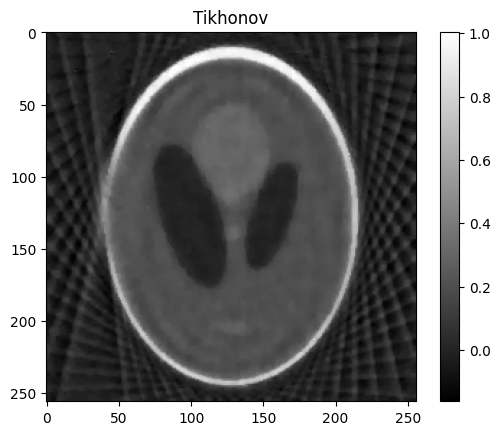

In [13]:
plt.imshow(resdata["x"].reshape((nx,ny)) , cmap="gray")
# plt.imshow(np.clip(vdata["x"].reshape((nx,ny)), a_min=0, a_max=None), cmap="gray")
plt.title("Tikhonov")
plt.colorbar()
plt.show()

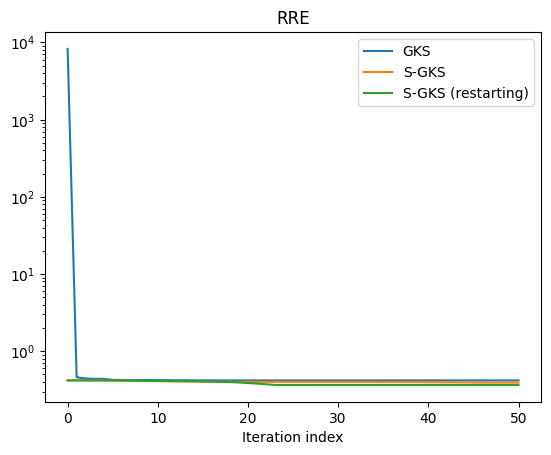

In [15]:
plt.semilogy(vdata["rre_history"], label="GKS")
#plt.semilogy(vdata_opt["rre_history"], label="$\\ell_2$-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(data["rre_history"], label="S-GKS")
plt.semilogy(resdata["rre_history"], label="S-GKS (restarting)")
#plt.semilogy(recdata["rre_history"], label="S-GKS (recycling)")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# Old

In [74]:
# pvdata = gks_solver.solve_with_priorconditioning(n_iter=50, init_dim=3, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
#                                                  regparam=method, x_true=x_true.flatten(), weight_params={},
#                                                  regparam_kwargs={"eta":1.03})

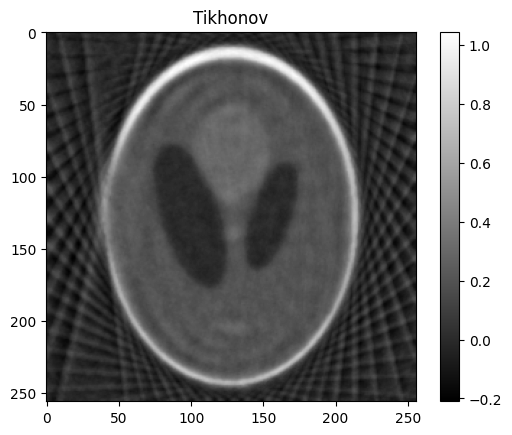

In [9]:
plt.imshow(vdata["x"].reshape((nx,ny)) , cmap="gray")
# plt.imshow(np.clip(vdata["x"].reshape((nx,ny)), a_min=0, a_max=None), cmap="gray")
plt.title("Tikhonov")
plt.colorbar()
plt.show()

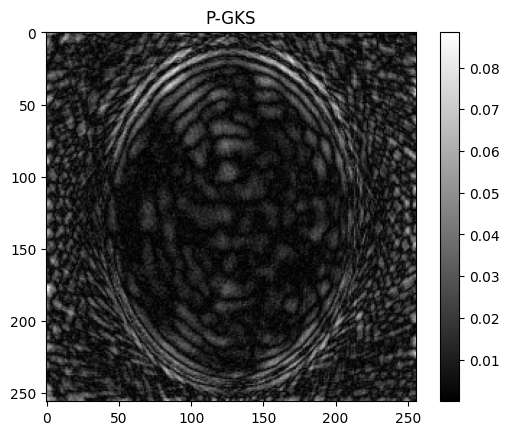

In [34]:
plt.imshow(np.abs( vdata["x"].reshape((nx,ny)) - pvdata["x"].reshape((nx,ny)) ), cmap="gray")
plt.title("P-GKS")
plt.colorbar()
plt.show()

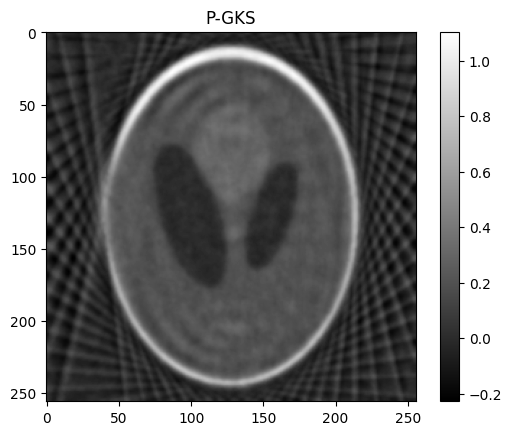

In [35]:
plt.imshow(pvdata["x"].reshape((nx,ny)), cmap="gray")
plt.title("P-GKS")
plt.colorbar()
plt.show()

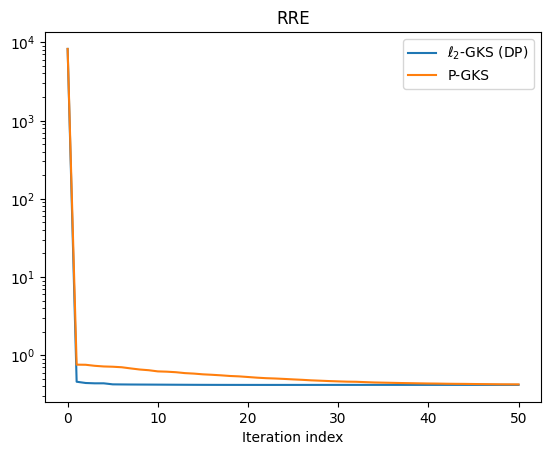

In [36]:
plt.semilogy(vdata["rre_history"], label="$\\ell_2$-GKS (DP)")
#plt.semilogy(vdata_opt["rre_history"], label="$\\ell_2$-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pvdata["rre_history"], label="P-GKS")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

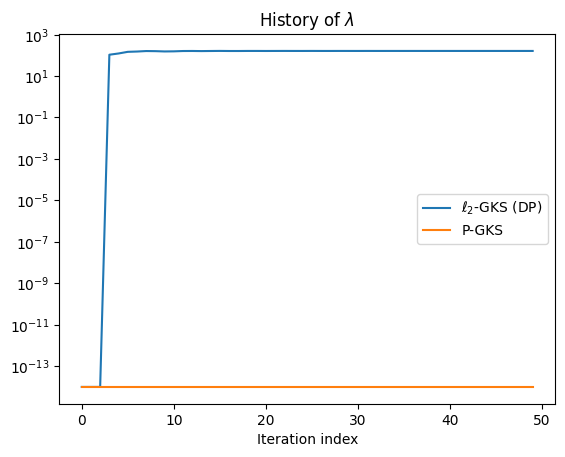

In [37]:
plt.semilogy(vdata["lambda_history"], label="$\\ell_2$-GKS (DP)")
#plt.semilogy(vdata_opt["lambda_history"], label="$\\ell_2$-GKS (optimal)", ls="--", alpha=0.7)
plt.semilogy(pvdata["lambda_history"], label="P-GKS")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

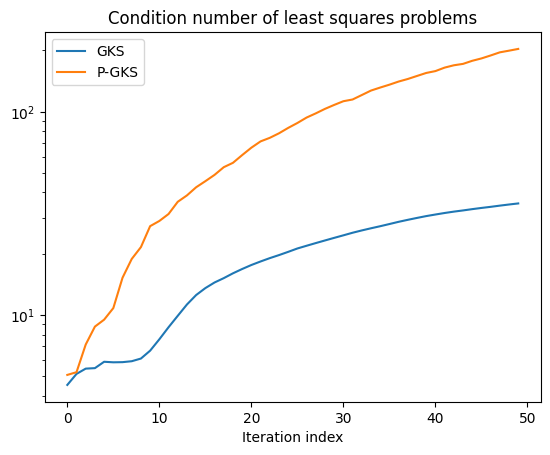

In [38]:
plt.semilogy(vdata["cond_ests"], label="GKS")
plt.semilogy(pvdata["cond_ests"], label="P-GKS")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

In [ ]:
vdata["dp_ineq_lhs"]

array([], dtype=float64)

# GKS method (GKS)

In [9]:
q = 1.0
epsilon = 1e-4
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

In [10]:
jlinops.build_neumann2d_sparse_matrix(img_shape)

<COOrdinate sparse matrix of dtype 'float64'
	with 261120 stored elements and shape (131072, 65536)>

In [11]:
# Set method
method = "dp"

Lmat = jlinops.build_neumann2d_sparse_matrix(img_shape)
L = jlinops.Neumann2D(img_shape)

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     delta = 1e-15
#     for j in range(10):
#         try:
#             return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=delta)
#         except:
#             delta *= 10
#     return None


K = np.ones(n)/np.linalg.norm(np.ones(n))
K = jlinops.MatrixLinearOperator(K)

#L = jlinops.Neumann2D(img_shape)
# def Lpinv_factory(w, *args, **kwargs):
#     return jlinops.CGWeightedNeumann2DPinvOperator(img_shape, weights=w, tol=1e-4, *args, **kwargs)

def Lpinv_factory(w, *args, **kwargs):
    return CGWeightedNeumann2DPinvOperatorGPU(img_shape, weights=w, tol=1e-8, *args, **kwargs)


#err_norm_sq = len(b) # in expectation


# Build solver
mmgks_solver = MMGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

In [12]:
data = mmgks_solver.solve(n_iter=50, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

Augmented basis with initial guess!


7.637935948492096
8.288337991774279
8.276538113048497
8.442594769786885
8.940060202458115
9.40060903393446
9.698331731344902
9.952317095029516
10.18509427112098
10.339173735471869
10.570326411690441
10.51353309884822
10.446067065768425
10.3387308931343
10.305560304159476
10.28975848385451
10.285535748441648
10.262589046539073
10.190514470805343
10.142824824574747
10.109702931898516
10.088998006376352
10.054971696507998
10.036716120031942
10.019348223500371
10.00273957814535
9.993009441871923
9.983784335322836
9.976188500249418
9.970149470720855
9.964564952295508
9.960835771599525
9.958150382128492
9.955234292467717
9.951788642059688
9.94888114943608
9.946430946629073
9.945610511887686
9.945263848637302
9.943848435524279
9.943420736530724
9.94335457825391
9.944576759186948
9.948230257968342
9.951892616135366
9.956853354726558
9.950924575976757
9.952044125304742
9.953894842510252
9.960979142959557


In [13]:
pdata = mmgks_solver.solve_with_priorconditioning(n_iter=20, init_dim=5, x0=vdata["x"], lambdah0=vdata["lambdah"], lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

Augmented basis with initial guess!


/home/jlindbloom/Github/IRLS_prec_GSBL/msolver.py:682: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14


In [58]:
# pdata2 = mmgks_solver.solve_with_priorconditioning(n_iter=15, init_dim=3, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
#                                                  regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
#                                                  regparam_kwargs={"eta":1.01})

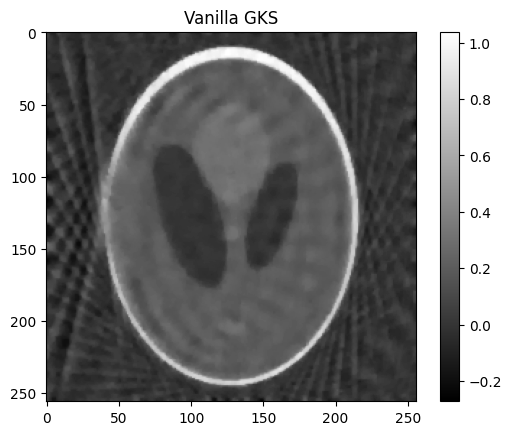

In [17]:
plt.imshow(data["x"].reshape((nx,ny)), cmap="gray")
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

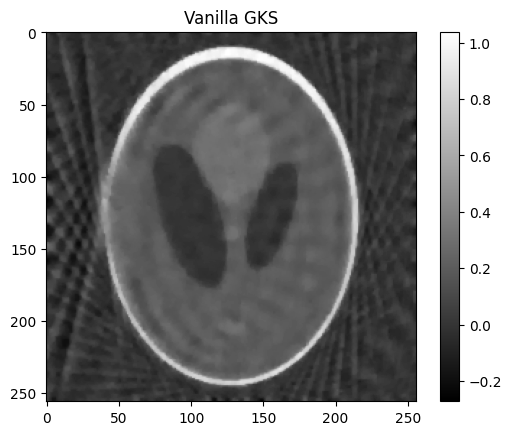

In [18]:
plt.imshow(data["x"].reshape((nx,ny)), cmap="gray")
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

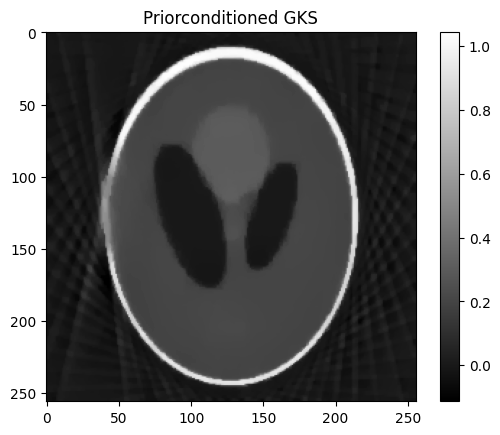

In [19]:
plt.imshow(pdata["x"].reshape((nx,ny)), cmap="gray")
plt.title("Priorconditioned GKS")
plt.colorbar()
plt.show()

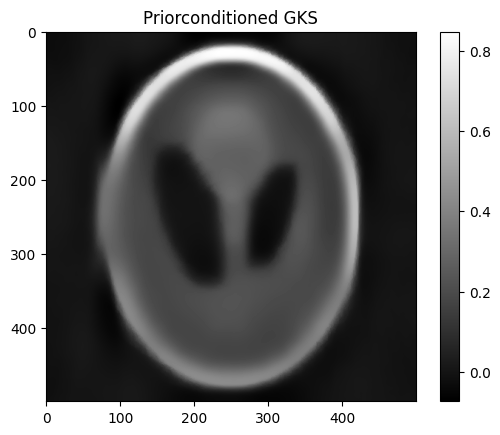

In [ ]:
plt.imshow(pdata2["x"].reshape((nx,ny)), cmap="gray")
plt.title("Priorconditioned GKS")
plt.colorbar()
plt.show()

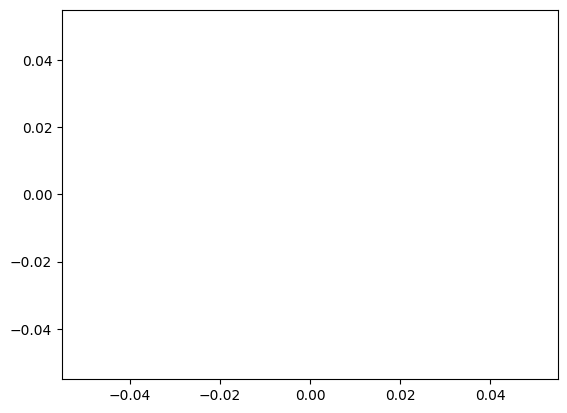

In [ ]:
plt.plot(data["dp_ineq_lhs"])
plt.plot(data["dp_ineq_chs"])
plt.plot(data["dp_ineq_rhs"])
plt.show()

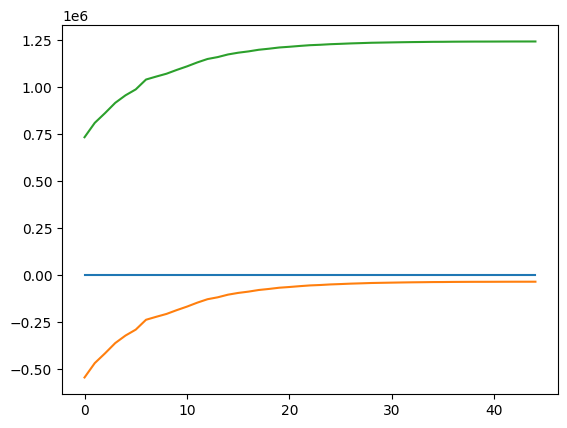

In [ ]:
plt.plot(pdata["dp_ineq_lhs"])
plt.plot(pdata["dp_ineq_chs"])
plt.plot(pdata["dp_ineq_rhs"])
plt.show()

NameError: name 'pdata' is not defined

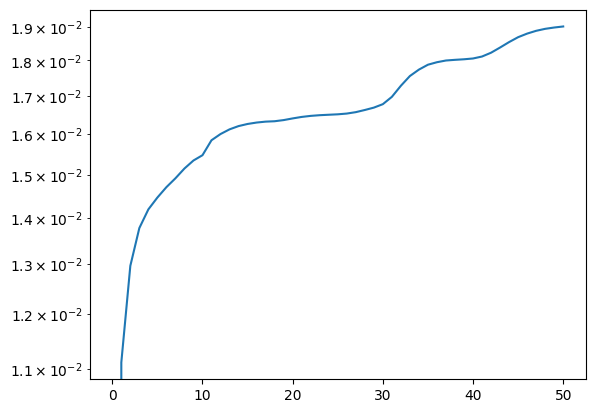

In [17]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

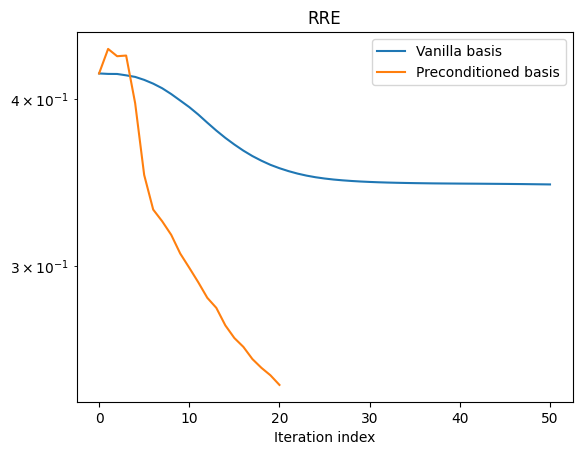

In [20]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

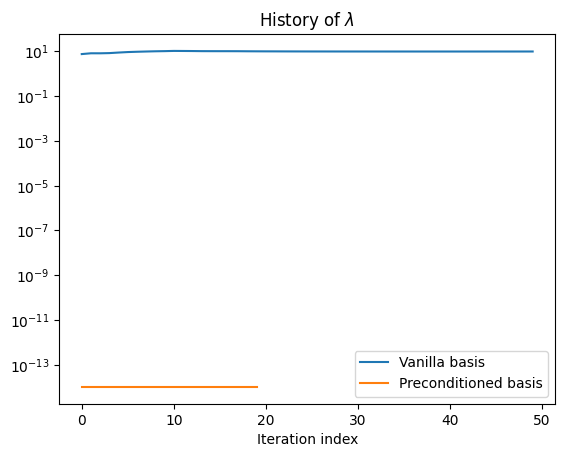

In [21]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

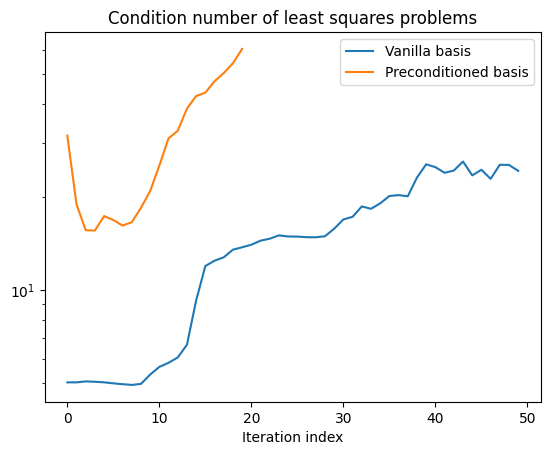

In [22]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# Basis plotting code

In [23]:
from matplotlib.backends.backend_pdf import PdfPages

In [24]:
images = [ data["V"][:,j].reshape((nx,ny)) for j in range(data["V"].shape[1]) ]
# Create a PDF file
pdf_filename = "tomo_mm_vanilla_basis2.pdf"
with PdfPages(pdf_filename) as pdf:
    for i, array in enumerate(images):
        plt.figure()
        plt.imshow(array, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Array {i+1}")
        pdf.savefig()  # Save the current figure to the PDF
        plt.close()  # Close the figure to avoid memory issues

In [25]:
# Create a PDF file
pdf_filename = "tomo_mm_preconditioned_basis2.pdf"
images = [ ( pdata["V"][:nx*ny,j].reshape((nx,ny)), pdata["V"][nx*ny:,j].reshape((nx,ny))   ) for j in range(pdata["V"].shape[1]) ]
with PdfPages(pdf_filename) as pdf:
    for i, (im1, im2) in enumerate(images):
        plt.figure(figsize=(10, 5))  # Create a figure with an appropriate size
        
        # Plot the first image (im1)
        plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
        plt.imshow(im1, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Vertical portion of basis vector, {i+1}")

        # Plot the second image (im2)
        plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
        plt.imshow(im2, cmap='plasma', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Horizontal portion of basis vector, {i+1}")
        
        # Save the current figure to the PDF
        pdf.savefig()
        plt.close()  # Close the figure to free up memory

print(f"Paired plots saved to {pdf_filename}")

Paired plots saved to tomo_mm_preconditioned_basis2.pdf


In [26]:
images = [ (pdata["Lopinv"] @ pdata["V"][:,j]).reshape((nx,ny)) for j in range(pdata["V"].shape[1]) ]
# Create a PDF file
pdf_filename = "tomo_mm_preconditioned_basis_transformed2.pdf"
with PdfPages(pdf_filename) as pdf:
    for i, array in enumerate(images):
        plt.figure()
        plt.imshow(array, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Array {i+1}")
        pdf.savefig()  # Save the current figure to the PDF
        plt.close()  # Close the figure to avoid memory issues

# Vanilla GKS

In [ ]:
from msolver import VanillaGKS

In [ ]:
vgks_solver = VanillaGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

In [ ]:
vdata = vgks_solver.solve(n_iter=80, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

1e-14
39.74925698834014
51.555147006282375
51.9776537180845
52.01917618283423
54.31608689502763
54.926859456190236
54.85031986336683
54.68977571718614
54.567205761387434
54.56899194279625
54.61103103038499
54.62549074376582
54.62036816241674
54.616606803497085
54.627969332254025
54.62773441235738
54.62419985286685
54.624176332194814
54.6249550931676
54.62517971775933
54.62511558020086
54.62521973607675
54.62524826499882
54.625216317601534
54.62517887132189
54.62518709120191
54.62519645337469
54.62519255908676
54.62519272096456
54.625197616533875
54.625195797671864
54.625193618576006
54.62519477005314
54.62519476562782
54.625194785080765
54.62519475786732
54.625194791002116
54.625194796135354
54.625194882545
54.62519465321533
54.62519497387251
54.6251950722617
54.62519500943127
54.62519499634609
54.6251949812602
54.62519475359726
54.62519505719461
54.625194504654004
54.62519410477593
54.62519372193581
54.625193200181975
54.62519427464434
54.625194903892314
54.6251941033002
54.6251940250

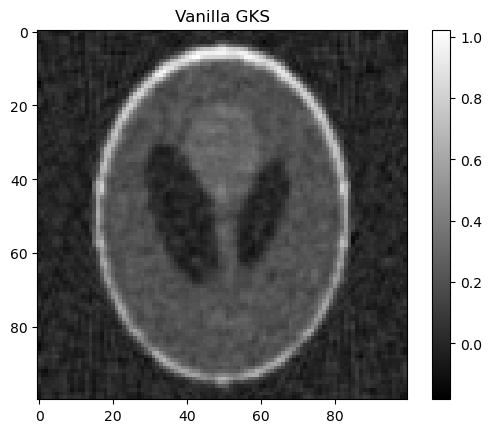

In [ ]:
plt.imshow(vdata["x"].reshape((nx,ny)), cmap="gray")
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

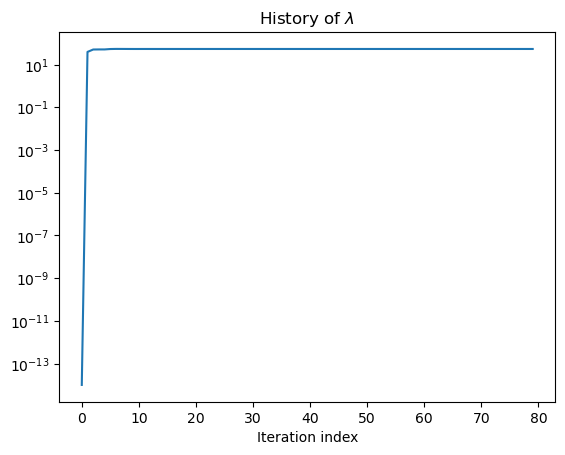

In [ ]:
plt.semilogy(vdata["lambda_history"], label="Vanilla basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
# plt.legend()
plt.show()

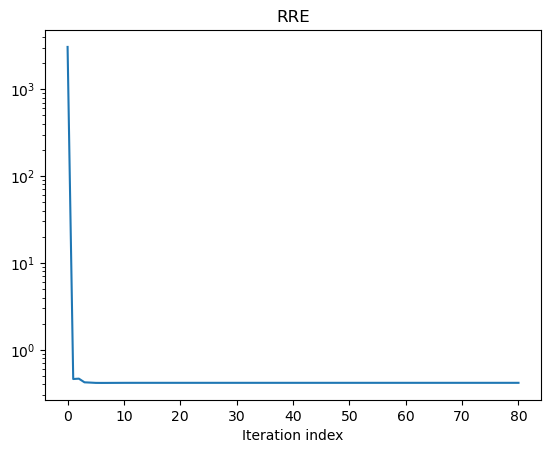

In [ ]:
plt.semilogy(vdata["rre_history"], label="Vanilla basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.show()

# IAS?

In [ ]:
weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

In [ ]:
# Build solver
iasgks_solver = IASGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

In [ ]:
data = iasgks_solver.solve(n_iter=120, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                    regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

1e-14
15.899702795336031
27.778113250979434
33.459792865267254
34.698417199629986
38.45544979717724
41.62128765784354
43.50525399167222
44.34171096681398
44.75646112942147
45.48688233734846
47.13133754792766
48.089378816345125
48.60414022954349
49.24072801354468
49.888304973959244
49.980123374444794
50.075732185704645
50.23005414236805
50.35216744596264
50.401642046052295
50.425641689904346
50.446342358907756
50.45878005000049
50.48233467149356
50.47896075832558
50.46736206823357
50.46318012698006
50.46823531141251
50.47237093826324
50.47695885381585
50.48952481430539
50.48354349524511
50.48651847991498
50.499688665961855
50.48499023275941
50.45349113610581
50.44730286169357
50.43158289481291
50.475525015216974
50.478665563865384
50.4848573601377
50.529014995459235
50.55556710967949
50.56406306541455
50.59536852077163
50.584705481010765
50.581712331703145
50.66515563675604
50.71055509557241
50.7004949472977
50.765444183577834
50.76094708304415
50.77855439926423
50.8047474417784
50.8098

In [ ]:
pdata = iasgks_solver.solve_with_priorconditioning(n_iter=120, init_dim=8, x0=data["x"], lambdah0=1e0, lambdah_min=1e-14, lambdah_max=1e7,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

1
[ -26.39072647  -22.64185451  -14.9824518  ... -119.04651418  -55.83180608
    0.        ]
2
[-3.99218332e-04 -4.04044181e-04 -3.93355072e-04 ...  7.25725146e-05
  5.09778228e-05  0.00000000e+00]
3
[-0.00038891 -0.00040148 -0.00038768 ...  0.00031863  0.00017633
  0.        ]
4
[-0.00038502 -0.00039883 -0.00038435 ...  0.00035756  0.00019604
  0.        ]
5
[-0.0003844  -0.0003984  -0.00038381 ...  0.00036411  0.00019934
  0.        ]
6
[-0.00038433 -0.00039836 -0.00038376 ...  0.00036542  0.00019999
  0.        ]
7
[-0.00038434 -0.00039836 -0.00038377 ...  0.00036587  0.00020022
  0.        ]


1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
1e-14
7.51188514435953
7.485032609282239
11.891708298793025
14.812758802318069
17.756502610108562
23.038061394135173
27.058008254921297
30.279228682418243
33.22294064880329
35.80603826069207
37.996557188698795
40.362107877050974
42.1623532370212
43.93419875108263
46.05913834777149
48.37889957036516
50.77251760401588
53.1260350043488
55.325711032775075
57.30866312486241
58.40595347346614
59.16469439514789
59.864426662476944
60.937477450508794
62.13823318164218
63.52952341285692
64.8560415171981
66.21363074157162
67.5570078070648
68.7581519546176
69.77012885477453
70.75382856482507
71.5584933216755
72.37470086608364
73.16469220210024
73.90487411407213
74.5035764194741
75.00286857414325
75.53617522644292
76.03685971168346
76.44525229581373
76.80271195348095
77.29151477116379
77.70507036489852
78.06530440758738
78.4698374459147
78

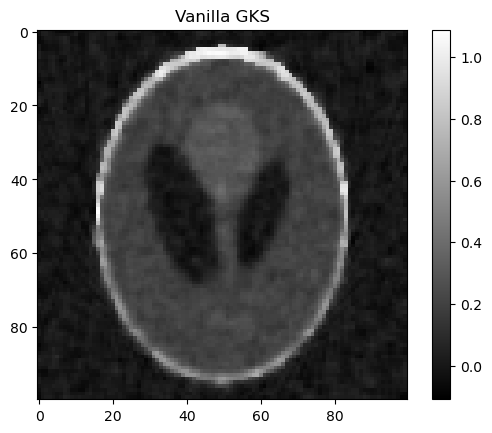

In [ ]:
plt.imshow(data["x"].reshape((nx,ny)), cmap="gray")
plt.title("Vanilla GKS")
plt.colorbar()
plt.show()

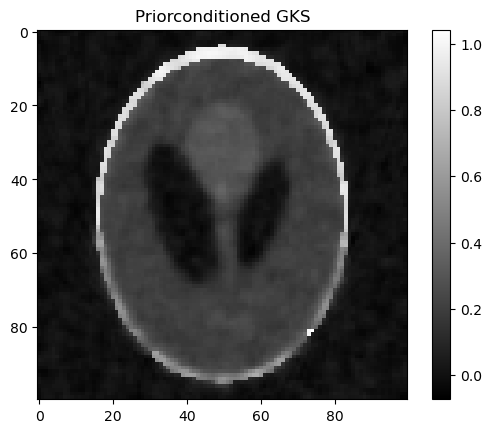

In [ ]:
plt.imshow(pdata["x"].reshape((nx,ny)), cmap="gray")
plt.title("Priorconditioned GKS")
plt.colorbar()
plt.show()

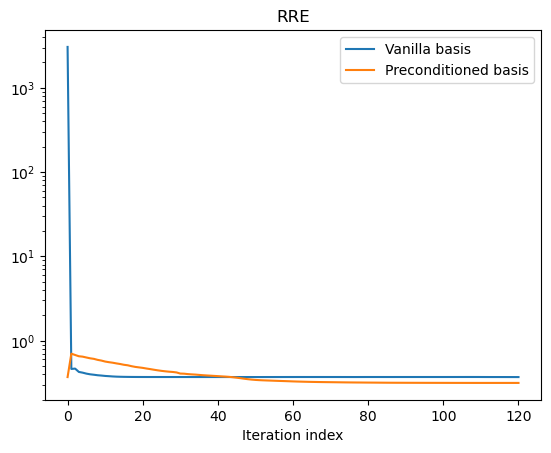

In [ ]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

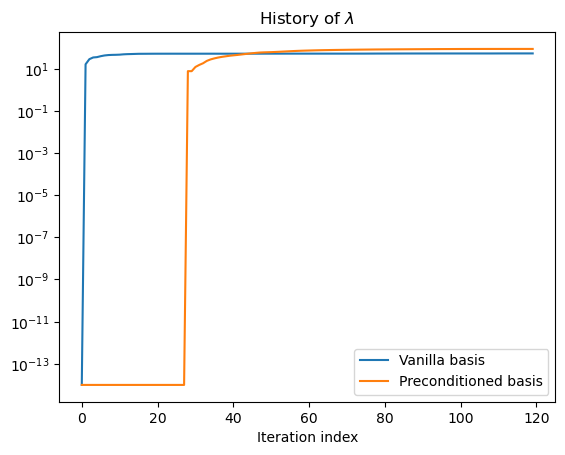

In [ ]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

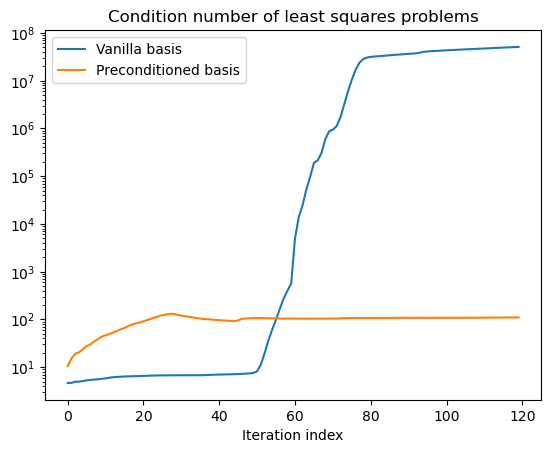

In [ ]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

In [ ]:
images = [ data["V"][:,j].reshape((nx,ny)) for j in range(data["V"].shape[1]) ]
# Create a PDF file
pdf_filename = "tomo_ias_vanilla_basis.pdf"
with PdfPages(pdf_filename) as pdf:
    for i, array in enumerate(images):
        plt.figure()
        plt.imshow(array, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Array {i+1}")
        pdf.savefig()  # Save the current figure to the PDF
        plt.close()  # Close the figure to avoid memory issues

In [ ]:
# Create a PDF file
pdf_filename = "tomo_ias_preconditioned_basis.pdf"
images = [ ( pdata["V"][:nx*ny,j].reshape((nx,ny)), pdata["V"][nx*ny:,j].reshape((nx,ny))   ) for j in range(pdata["V"].shape[1]) ]
with PdfPages(pdf_filename) as pdf:
    for i, (im1, im2) in enumerate(images):
        plt.figure(figsize=(10, 5))  # Create a figure with an appropriate size
        
        # Plot the first image (im1)
        plt.subplot(1, 2, 1)  # 1 row, 2 columns, 1st subplot
        plt.imshow(im1, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Vertical portion of basis vector, {i+1}")

        # Plot the second image (im2)
        plt.subplot(1, 2, 2)  # 1 row, 2 columns, 2nd subplot
        plt.imshow(im2, cmap='plasma', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Horizontal portion of basis vector, {i+1}")
        
        # Save the current figure to the PDF
        pdf.savefig()
        plt.close()  # Close the figure to free up memory

print(f"Paired plots saved to {pdf_filename}")

Paired plots saved to tomo_ias_preconditioned_basis.pdf


In [ ]:
images = [ (pdata["Lopinv"] @ pdata["V"][:,j]).reshape((nx,ny)) for j in range(pdata["V"].shape[1]) ]
# Create a PDF file
pdf_filename = "tomo_ias_preconditioned_basis_transformed.pdf"
with PdfPages(pdf_filename) as pdf:
    for i, array in enumerate(images):
        plt.figure()
        plt.imshow(array, cmap='viridis', aspect='auto')
        plt.colorbar()  # Optional: Add a color bar to show the scale
        plt.title(f"Array {i+1}")
        pdf.savefig()  # Save the current figure to the PDF
        plt.close()  # Close the figure to avoid memory issues